<p align="center">
    <img src="https://github.com/GeostatsGuy/GeostatsPy/blob/master/TCG_color_logo.png?raw=true" width="220" height="240" />
</p>

## Class Overlap or Model Limit? Statistical Separability, Bayes Error and a Reject Option for Fault Diagnosis in a Simulated Elbow Exoskeleton

#### Aman Sanadhya
#### Walker Department of Mechanical Engineering, Cockrell School of Engineering, The University of Texas at Austin

### Subsurface Machine Learning Course, The University of Texas at Austin
#### Hildebrand Department of Petroleum and Geosystems Engineering, Cockrell School of Engineering
#### Department of Geological Sciences, Jackson School of Geosciences

_____________________

Workflow supervision and review by:

#### Instructor: Prof. Michael Pyrcz, Ph.D., P.Eng., Associate Professor, The University of Texas at Austin
[Twitter](https://twitter.com/geostatsguy) | [GitHub](https://github.com/GeostatsGuy) | [Website](http://michaelpyrcz.com) | [GoogleScholar](https://scholar.google.com/citations?user=QVZ20eQAAAAJ&hl=en&oi=ao) | [Geostatistics Book](https://www.amazon.com/Geostatistical-Reservoir-Modeling-Michael-Pyrcz/dp/0199731446) | [YouTube](https://www.youtube.com/channel/UCLqEr-xV-ceHdXXXrTId5ig)  | [Applied Geostats in Python e-book](https://geostatsguy.github.io/GeostatsPyDemos_Book/intro.html) | [Applied Machine Learning in Python e-book](https://geostatsguy.github.io/MachineLearningDemos_Book/) | [LinkedIn](https://www.linkedin.com/in/michael-pyrcz-61a648a1)

#### Course TA: Alex Ikenaike, Graduate Student, The University of Texas at Austin

### Executive Summary

When classes overlap in the measured features no classifier can separate them, so a model that always answers will be wrong without warning, yet a weak model or too little data can look exactly like overlap. I built a simulated wearable elbow exoskeleton in which six causes (healthy, sensor offset, sensor drift, loose strap, weaker motor, extra load) must be told apart from sensor signals, added wearer and battery variation at four levels to create overlap, and tested every pair of causes with five model families on fault sizes never seen in training. Up to moderate variation (s = 2) the best model separated every pair above 0.95 balanced accuracy: the apparent ceilings were small-data effects exposed by learning curves, and one real overlap (forearm mass hiding an extra load) was confirmed by removing it; at doubled variation (s = 4) healthy vs weaker motor stayed at 0.86 with two different seeds while its learning curve flattened, which is consistent with true overlap. Letting the model say "not sure" below a fixed confidence raised accuracy on answered cases from 0.963 to 0.984 while answering 92% of cases, and an interactive simulator lets a reader explore single trials. Before calling classes inseparable, check the train-test gap, a learning curve, agreement between model families, a targeted ablation and a second random seed, and let a deployed classifier abstain when unsure.

Code and data (all generated in this notebook): [github.com/AmanSanadhya](https://github.com/AmanSanadhya)

### Import Packages

* only what the workflow needs, with the reason in each comment

In [1]:
import numpy as np                                        # arrays and random numbers
import pandas as pd                                       # tables of simulated trials
import matplotlib.pyplot as plt                           # plots
from matplotlib.animation import FuncAnimation, PillowWriter  # frame-by-frame animations, written as GIFs
import io, base64                                         # GIFs built in memory and stored in the notebook as text
from IPython.display import display                       # show a GIF together with a still frame for PDF export
try:
    import ipywidgets as widgets                          # dropdown, sliders and button for the interactive simulator
except ImportError:
    widgets = None                                        # optional: without it, step 7 shows only the static snapshot
from math import sin, cos, tanh, pi                       # fast scalar math inside the simulator loop
from itertools import combinations                        # every pair of causes
from scipy.stats import norm                              # normal distribution, for the toy example's best possible accuracy
from joblib import Parallel, delayed                      # run simulated trials and pair tests on all CPU cores
from sklearn.naive_bayes import GaussianNB                # the five models from class
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline                # scaling + model in one step, so scaling is fit on training data only
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score       # 1.0 = perfect, 0.5 = coin flip for two classes
import warnings; warnings.filterwarnings("ignore")        # hide convergence notices to keep the output short
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

### Functions

* a small physics simulator, so the true cause is known and anyone can regenerate the data
* my own compact rewrite of my earlier exoskeleton diagnosis code, with placeholder parameters, not a real device; all code in this notebook is my own unless cited
* split into five short blocks

* **Block 1, parameters:** nominal elbow, exoskeleton and strap values, the six causes, and the wearer and battery variation that creates overlap

In [2]:
# nominal physical parameters of the simulated elbow + exoskeleton (placeholder values, SI units)
NOM = dict(J_h=0.06, m_h=1.5, l_h=0.15, k_h=15.0, b_h=1.0, m_load=0.0, l_load=0.30,   # forearm: inertia, mass, lever arm, stiffness, damping, extra load
           J_e=0.02, b_e=0.05, tau_c=0.05,                                               # exoskeleton link: inertia, friction
           k_s=40.0, c_s=0.5, delta=0.01, T0=20.0, r_s=0.05,                             # strap: stiffness, damping, slack, preload, moment arm
           kt=0.30, gain=1.0, tau_a=0.010, i_max=8.0,                                    # motor: torque per amp, gain, lag, current limit
           enc_bias=0.0, enc_drift=0.0)                                                  # angle sensor offset and drift
KP, KD, G = 8.0, 0.4, 9.81                                                               # exoskeleton controller gains, gravity
SENSORS = {"encoder": (1e-3, 2*pi/4096), "gyro": (2e-2, 0.0), "current": (5e-2, 0.01),
           "int_torque": (5e-2, 0.0), "strap_tension": (5e-1, 0.0)}                      # (noise standard deviation, rounding step)
MOTIONS = {"slow": (1.0, ((0.5, 0.2),)),                                                 # mean angle, then (amplitude, Hz) pairs
           "multisine": (1.0, ((0.2, 0.2), (0.1, 0.7), (0.05, 1.5)))}
TYPICAL = {"encoder_bias": 0.03, "encoder_drift": 0.003, "interface_looseness": 0.5,
           "actuator_gain_loss": 0.3, "load_mass": 0.5}                                  # size of each cause at multiplier 1.0
CAUSES = ["healthy"] + list(TYPICAL)
SPREAD = dict(k_h=0.20, b_h=0.20, m_h=0.10, gain=0.04)                                   # wearer / battery variation at s = 1 (relative spread)

def make_params(cause, size, seed, s, spread=SPREAD):
    """Physical parameters for one trial: the cause at its size, plus random wearer and battery variation scaled by s."""
    p, v = dict(NOM), size * TYPICAL.get(cause, 0.0)
    if cause == "encoder_bias":        p["enc_bias"] = v
    if cause == "encoder_drift":       p["enc_drift"] = v
    if cause == "load_mass":           p["m_load"] = v
    if cause == "actuator_gain_loss":  p["gain"] = 1.0 - v
    if cause == "interface_looseness": p.update(k_s=40.0*(1 - 0.6*v), c_s=0.5*(1 - 0.3*v),   # a loose strap changes several strap properties together
                                                delta=max(0.01 + 0.03*v, 1e-4), T0=20.0*(1 - v))
    if s > 0:
        r = np.random.default_rng(seed + 1)                                              # separate random stream for the wearer
        p["k_h"] *= max(0.2, 1 + s*spread["k_h"]*r.standard_normal())                    # arm stiffness (muscle fatigue)
        p["b_h"] *= max(0.2, 1 + s*spread["b_h"]*r.standard_normal())                    # arm damping
        p["m_h"] *= max(0.5, 1 + s*spread["m_h"]*r.standard_normal())                    # forearm mass
        p["gain"] *= max(0.5, 1 - abs(s*spread["gain"]*r.standard_normal()))             # battery sag lowers motor torque
    return p

* **Block 2, physics:** forearm (stiffness, damping, gravity), strap with a slack zone, and a motor with lag

In [3]:
def smooth_deadzone(x, d):
    d = max(d, 1e-6)
    return x - d*tanh(x/d)                                                               # strap is slack within +-d, taut outside

def derivatives(state, q_ref, w_ref, i_cmd, p):
    """Rates of change of (forearm angle, speed, exo angle, speed, motor torque), and the torque across the strap."""
    q_h, w_h, q_e, w_e, tau_m = state
    tau_strap = p["k_s"]*smooth_deadzone(q_e - q_h, p["delta"]) + p["c_s"]*(w_e - w_h)
    J_tot = p["J_h"] + p["m_load"]*p["l_load"]**2
    tau_arm = (NOM["m_h"]*G*NOM["l_h"]*sin(q_ref) + p["k_h"]*(q_ref - q_h)                # wearer follows the motion and offsets the NOMINAL arm's gravity
               + p["b_h"]*(w_ref - w_h))
    gravity = (p["m_h"]*p["l_h"] + p["m_load"]*p["l_load"])*G*sin(q_h)
    d_w_h = (tau_arm + tau_strap - gravity)/J_tot
    d_w_e = (tau_m - p["b_e"]*w_e - p["tau_c"]*tanh(w_e/0.01) - tau_strap)/p["J_e"]
    d_tau_m = (p["gain"]*p["kt"]*i_cmd - tau_m)/p["tau_a"]                                # motor torque lags the current command
    return (w_h, d_w_h, w_e, d_w_e, d_tau_m), tau_strap

def shift(state, rate, h):
    return tuple(x + h*dx for x, dx in zip(state, rate))

* **Block 3, simulation:** one 10 s trial with a standard 4th-order Runge-Kutta step and noisy, rounded sensors; the controller only sees the sensors, so a faulty sensor really misleads it; it can also return the true angles and strap torque, used only for drawing and never as features

In [4]:
def simulate(p, motion, seed, T=10.0, dt=0.002, return_truth=False):
    """One 10 s trial (Runge-Kutta 4). Returns the time stamps and the five noisy sensor signals
    (and, if return_truth, the true forearm, exoskeleton and commanded angles and strap torque, for drawing only)."""
    q0, sines = MOTIONS[motion]
    ref_q = lambda t: q0 + sum(a*sin(2*pi*f*t) for a, f in sines)                         # commanded angle
    ref_w = lambda t: sum(a*2*pi*f*cos(2*pi*f*t) for a, f in sines)                       # commanded speed
    rng = np.random.default_rng(seed)
    def read(name, value):                                                                # add sensor noise and rounding to a true value
        std, step = SENSORS[name]
        v = value + std*rng.standard_normal()
        return step*round(v/step) if step > 0 else v
    n = int(round(T/dt)); state = (ref_q(0.0), ref_w(0.0), ref_q(0.0), ref_w(0.0), 0.0)
    sig = {k: np.empty(n) for k in ["enc_err", "gyro", "current", "int_torque", "strap_tension"]}
    truth = {k: np.empty(n) for k in ["q_arm", "q_exo", "q_ref", "tau_strap"]}           # true values, never used as features
    for k in range(n):
        t = k*dt; q_r, w_r = ref_q(t), ref_w(t)
        enc = read("encoder", state[2] + p["enc_bias"] + p["enc_drift"]*t)                # angle sensor, may be offset or drifting
        gyro = read("gyro", state[1])                                                     # speed sensor on the forearm
        i_cmd = max(-p["i_max"], min(p["i_max"], (KP*(q_r - enc) + KD*(w_r - gyro))/p["kt"]))   # controller trusts the sensors
        _, tau_strap = derivatives(state, q_r, w_r, i_cmd, p)
        sig["enc_err"][k], sig["gyro"][k] = enc - q_r, gyro
        sig["current"][k] = read("current", i_cmd)
        sig["int_torque"][k] = read("int_torque", tau_strap)
        sig["strap_tension"][k] = read("strap_tension", p["T0"] + tau_strap/p["r_s"])
        truth["q_arm"][k], truth["q_exo"][k], truth["q_ref"][k], truth["tau_strap"][k] = state[0], state[2], q_r, tau_strap
        q_m, w_m, q_n, w_n = ref_q(t + dt/2), ref_w(t + dt/2), ref_q(t + dt), ref_w(t + dt)
        k1, _ = derivatives(state, q_r, w_r, i_cmd, p)                                    # four slope estimates, combined below
        k2, _ = derivatives(shift(state, k1, dt/2), q_m, w_m, i_cmd, p)
        k3, _ = derivatives(shift(state, k2, dt/2), q_m, w_m, i_cmd, p)
        k4, _ = derivatives(shift(state, k3, dt), q_n, w_n, i_cmd, p)
        state = tuple(x + dt/6*(a + 2*b + 2*c + d) for x, a, b, c, d in zip(state, k1, k2, k3, k4))
    return (np.arange(n)*dt, sig, truth) if return_truth else (np.arange(n)*dt, sig)

* **Block 4, features and dataset:** each trial becomes 5 numbers (mean, spread, slope, min, max) for each of 5 sensor channels; every trial gets its own noise seed so noise is never shared between training and test

In [5]:
STATS = ["mean", "std", "slope", "min", "max"]

def summarize(t, signals, burn=1.0):
    """25 numbers per trial: mean, spread, trend (slope), min and max of each sensor, skipping the first second (start-up transient)."""
    keep = t >= burn; tt = t[keep] - t[keep].mean(); row = {}
    for name, x in signals.items():
        x = x[keep]
        row.update({f"{name}_mean": x.mean(), f"{name}_std": x.std(), f"{name}_slope": np.polyfit(tt, x, 1)[0],
                    f"{name}_min": x.min(), f"{name}_max": x.max()})
    return row

def run_trial(job):
    cause, size, motion, split, seed, s, spread = job
    t, signals = simulate(make_params(cause, size, seed, s, spread), motion, seed)
    return {**summarize(t, signals), "cause": cause, "size": size, "motion": motion, "split": split, "s": s}

def make_dataset(motion, s, train_reps, test_reps, n_healthy_train, n_healthy_test, test_sizes=(0.75, 1.25),
                 causes=tuple(TYPICAL), spread=SPREAD, master_seed=383):
    """Simulate a dataset. Training sizes are 0.5, 1 and 1.5 x typical, and test sizes are different, so they are never seen in training."""
    recipes = []
    for split, sizes, reps, n_healthy in [("train", (0.5, 1.0, 1.5), train_reps, n_healthy_train),
                                          ("test", test_sizes, test_reps, n_healthy_test)]:
        recipes += [(c, z, split) for c in causes for z in sizes for _ in range(reps)]
        recipes += [("healthy", 0.0, split)]*n_healthy
    seeds = np.random.default_rng(master_seed).choice(2**31 - 2, len(recipes), replace=False)   # one unique noise seed per trial
    jobs = [(c, z, motion, split, int(sd), s, spread) for (c, z, split), sd in zip(recipes, seeds)]
    return pd.DataFrame(Parallel(n_jobs=-1)(delayed(run_trial)(j) for j in jobs))

**Helper functions for models and plots**

* training uses fault sizes 0.5, 1.0 and 1.5 times typical; testing uses 0.75 and 1.25 times, so the model must interpolate to sizes it has not seen
* pairs are scored with balanced accuracy, the mean recall of the two classes, $\tfrac{1}{2}\left(\tfrac{TP}{TP+FN}+\tfrac{TN}{TN+FP}\right)$: 1.0 is perfect, 0.5 is a coin flip
* neural nets are capped at 600 iterations and some stop before full convergence; the warning is hidden to keep the output short
* learning_curve() refits a pair on random training subsets of growing size (five per size)

In [6]:
SHORT = {"healthy": "Healthy", "encoder_bias": "Sensor offset", "encoder_drift": "Sensor drift",
         "interface_looseness": "Loose strap", "actuator_gain_loss": "Weaker motor", "load_mass": "Extra load"}
COLOR = {"healthy": "#666666", "encoder_bias": "#0072B2", "encoder_drift": "#56B4E9",
         "interface_looseness": "#009E73", "actuator_gain_loss": "#E69F00", "load_mass": "#D55E00"}
MAIN = ["enc_err", "gyro", "current", "int_torque"]          # sensor channels used for the main results (strap tension is tested separately)

def model_zoo():
    """The five model families from class, each with sensible settings."""
    return {"Naive Bayes": GaussianNB(priors=[.5, .5]),
            "Tree": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=0),
            "SVM": make_pipeline(StandardScaler(), SVC(C=10, class_weight="balanced")),
            "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
            "Neural net": make_pipeline(StandardScaler(), MLPClassifier((32, 32), max_iter=600, random_state=0))}

def channel_columns(df, channels):
    return [c for c in df.columns if any(c.startswith(ch + "_") for ch in channels)]

def fit_pair(df, a, b, cols, name, model, n_train=None, seed=0):
    """Train on cause a vs cause b (seen fault sizes), score on unseen sizes. Returns train and test balanced accuracy."""
    tr, te = df[df.split == "train"], df[df.split == "test"]
    tr, te = tr[tr.cause.isin([a, b])], te[te.cause.isin([a, b])]
    if n_train: tr = tr.sample(n_train, random_state=seed)                      # for learning curves
    ytr, yte = (tr.cause == b).astype(int), (te.cause == b).astype(int)
    warnings.filterwarnings("ignore")                                           # silence neural-net convergence notices inside the worker processes
    model.fit(tr[cols].values, ytr)
    return dict(a=a, b=b, model=name, n=len(tr), seed=seed,
                train=balanced_accuracy_score(ytr, model.predict(tr[cols].values)),
                test=balanced_accuracy_score(yte, model.predict(te[cols].values)))

def pair_scores(df, cols, names=None):
    """Balanced accuracy for every pair of causes and every model (run in parallel)."""
    zoo = model_zoo(); names = names or list(zoo)
    jobs = [(a, b, n) for a, b in combinations(CAUSES, 2) for n in names]
    return pd.DataFrame(Parallel(n_jobs=-1)(delayed(fit_pair)(df, a, b, cols, n, model_zoo()[n]) for a, b, n in jobs))

def draw_pair_map(ax, scores, title):
    """Lower-triangle heat map of test accuracy (best of the five models) for every pair of causes."""
    M = np.full((6, 6), np.nan)
    for (a, b), v in scores.groupby(["a", "b"]).test.max().items(): M[CAUSES.index(b), CAUSES.index(a)] = v
    im = ax.imshow(M, vmin=0.9, vmax=1.0, cmap="viridis")
    for i in range(6):
        for j in range(6):
            if not np.isnan(M[i, j]): ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if M[i, j] < 0.96 else "black")
    ax.set_xticks(range(6)); ax.set_yticks(range(6))
    ax.set_xticklabels([SHORT[c].replace(" ", "\n") for c in CAUSES], fontsize=7); ax.set_yticklabels([SHORT[c] for c in CAUSES], fontsize=7)
    ax.set_title(title, fontsize=9); return im

def learning_curve(df, a, b, cols, sizes, models=("SVM", "Neural net"), reps=5):
    """Test balanced accuracy against training-set size: mean and spread over random training subsets."""
    runs = Parallel(n_jobs=-1)(delayed(fit_pair)(df, a, b, cols, n, model_zoo()[n], n_train=sz, seed=r)
                               for n in models for sz in sizes for r in range(reps))
    return pd.DataFrame(runs).groupby(["model", "n"]).test.agg(["mean", "std"]).reset_index()

* **Block 5, drawing:** a forearm and exoskeleton sketch with a strap gauge (used by the arm animation and the interactive simulator), and a GIF writer that works in memory, so no file is saved

In [7]:
L_ARM, L_CUFF = 0.30, 0.20                                               # drawing lengths (m): elbow to hand, elbow to strap

class MemoryGIF(PillowWriter):                                           # PillowWriter checks for a folder on disk; skip that so it can write to memory
    def setup(self, fig, outfile, dpi=None): super().setup(fig, ".", dpi); self.outfile = outfile

def at(q, r):                                                            # point r along a link at angle q (q = 0 hangs straight down)
    return [0, r*np.sin(q)], [0, -r*np.cos(q)]

def draw_arm(ax, gauge, truth, k, p, title):
    """Forearm, exoskeleton link and strap at sample k, plus a gauge of strap stretch against the slack zone."""
    q_arm, q_exo, q_ref = truth["q_arm"][k], truth["q_exo"][k], truth["q_ref"][k]
    stretch, slack = np.degrees(q_exo - q_arm), np.degrees(p["delta"])
    taut = abs(stretch) > slack
    ax.cla(); gauge.cla()
    ax.plot([0, 0], [0, 0.25], color="#BBBBBB", lw=7, solid_capstyle="round")                    # upper arm (fixed)
    ax.plot(*at(q_ref, L_ARM), color="#999999", ls="--", lw=1, label="commanded angle")
    ax.plot(*at(q_arm, L_ARM), color="#444444", lw=7, solid_capstyle="round", label="forearm")
    ax.plot(*at(q_exo, L_ARM*0.9), color="#0072B2", lw=2.5, label="exoskeleton link")
    x, y = at(q_arm, L_CUFF)
    ax.plot(x[1], y[1], "s", ms=9, color="#D55E00" if taut else "#56B4E9", label="strap: taut" if taut else "strap: slack")
    if p["m_load"] > 0: ax.plot(*[v[1] for v in at(q_arm, L_ARM)], "s", ms=12, color="#D55E00", label="extra load")
    ax.plot(0, 0, "o", color="black", ms=5)                              # elbow
    ax.set(xlim=(-0.08, 0.36), ylim=(-0.32, 0.27), aspect="equal", xlabel="horizontal (m)", ylabel="vertical (m)",
           title=f"{title}\narm minus command {np.degrees(q_arm - q_ref):+.1f} deg")
    ax.legend(frameon=False, fontsize=6, loc="upper right")
    gauge.axvspan(-slack, slack, color="#DDDDDD", label="slack zone")
    gauge.plot(stretch, 0, "o", ms=8, color="#D55E00" if taut else "#56B4E9")
    gauge.set(xlim=(-1.6, 1.6), ylim=(-1, 1), yticks=[], xlabel="strap stretch, exo minus arm (deg)")
    gauge.legend(frameon=False, fontsize=6, loc="upper left")

### Load Data (Synthetic, Generated Inside This Notebook)

* **Causes (6 classes):** healthy; sensor offset (angle sensor reads a constant amount too high); sensor drift (angle sensor error grows with time); loose strap (weaker, sloppier link between arm and exoskeleton); weaker motor (lower torque per amp); extra load (added mass on the forearm)
* **Sensor channels (5):** angle error, angular speed, motor current, strap torque, strap tension; features are in radians, rad/s, amps, N·m and N
* **Wearer and battery variation, scale s:** arm stiffness and damping (20% at s = 1), forearm mass (10%) and motor strength lost to battery sag (4%) change from trial to trial; larger s means more overlap. These spreads are my choices for the experiment, not measured values
* **Seeds:** fixed (1 to 4 for the datasets, 383 for the toy example) so results repeat; no data files are needed

The traces below show why the problem is hard: only some causes look different by eye.

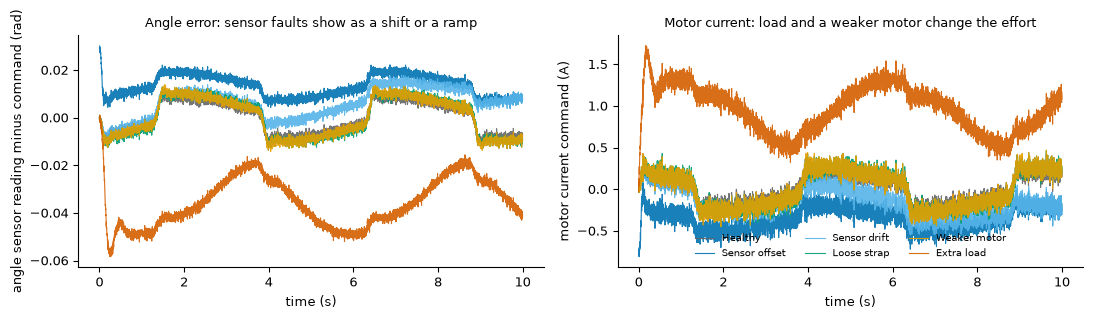

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
for c in CAUSES:                                                         # one 10 s trial per cause, typical size, no wearer variation
    t, sig = simulate(make_params(c, 1.0, 7, 0.0), "slow", 7)
    for ax, ch in zip(axs, ["enc_err", "current"]):
        ax.plot(t, sig[ch], color=COLOR[c], lw=0.8, label=SHORT[c], alpha=0.9)
axs[0].set_ylabel("angle sensor reading minus command (rad)"); axs[1].set_ylabel("motor current command (A)")
for ax in axs: ax.set_xlabel("time (s)")
axs[0].set_title("Angle error: sensor faults show as a shift or a ramp", fontsize=9)
axs[1].set_title("Motor current: load and a weaker motor change the effort", fontsize=9)
axs[1].legend(frameon=False, fontsize=7, ncol=3, loc="lower center"); fig.tight_layout(); plt.show()

* **Animation:** the same three trials as the traces above (typical fault size, no wearer variation, seed 7), drawn as forearm and exoskeleton in 40 frames from 1.25 s to 10 s
* dark bar: forearm; blue line: exoskeleton link; dashed line: commanded angle; the square on the forearm is the strap, orange when taut and light blue when slack
* bottom gauge: strap stretch (exoskeleton minus forearm angle) against the slack zone; healthy and loose strap stay inside their slack zones (the loose one is wider), while the extra load pulls the arm about 4 degrees below the command and at times stretches the strap past its slack zone
* the stretch is under 1.2 degrees, too small to see in the drawing, so it is shown on the gauge rather than exaggerated; the true angles come from simulate(..., return_truth=True) and are never used as features
* the GIF is built in memory and stored in the notebook; the PDF shows only the first frame (t = 1.2 s)

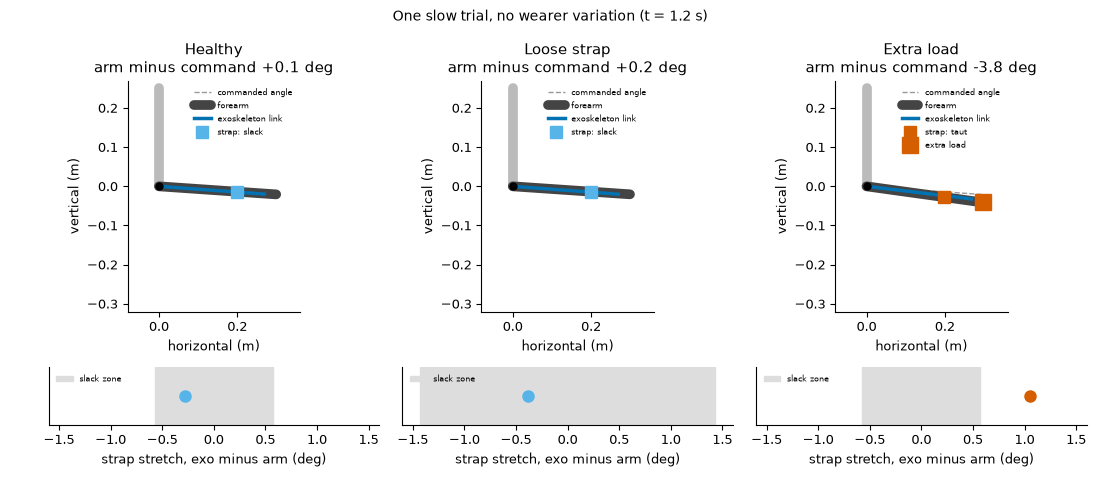

In [9]:
SHOW = ["healthy", "interface_looseness", "load_mass"]                   # same trials as the traces above: typical size, s = 0, seed 7
params = {c: make_params(c, 1.0, 7, 0.0) for c in SHOW}
runs = {c: simulate(params[c], "slow", 7, return_truth=True) for c in SHOW}
times = np.linspace(1.25, 9.998, 40)                                     # 40 frames; start at 1.25 s, where the arm is highest and the load pulls hardest
afig, aax = plt.subplots(2, 3, figsize=(11, 4.8), gridspec_kw={"height_ratios": [4, 1]})

def arm_frame(j):                                                        # one frame: redraw all three arms at the same moment
    k = int(round(times[j]/0.002))
    for col, c in enumerate(SHOW): draw_arm(aax[0, col], aax[1, col], runs[c][2], k, params[c], SHORT[c])
    afig.suptitle(f"One slow trial, no wearer variation (t = {times[j]:.1f} s)", fontsize=10)

arm_frame(0); afig.tight_layout()
gif = io.BytesIO(); gif.name = "arm.gif"                                 # in-memory buffer; the name only tells Pillow to encode a GIF
FuncAnimation(afig, arm_frame, frames=len(times)).save(gif, writer=MemoryGIF(fps=4))    # 40 frames at 4 per second = 10 s
arm_frame(0); still = io.BytesIO(); afig.savefig(still, format="png"); plt.close(afig)   # frame 1 as a PNG, for the PDF export
display({"text/html": f'<img src="data:image/gif;base64,{base64.b64encode(gif.getvalue()).decode()}">',   # animated in Jupyter and VS Code
         "image/png": base64.b64encode(still.getvalue()).decode()}, raw=True)                                # still frame where HTML is not shown

### Theory: Why Some Classes Cannot Be Separated

* **Class overlap:** where the feature distributions of two classes share the same region, the true class cannot be known from the features alone
* **Bayes (irreducible) error:** the best rule picks the most likely class at each point, $\hat{y}(x)=\arg\max_k P(y=k \mid x)$; its error, $E\left[1-\max_k P(y=k \mid x)\right]$, is the overlap, and no model, however flexible, beats it on average
* **Model limit vs data limit:** a weak model underfits (naive Bayes assumes independent features; a shallow tree has few splits); a flexible model can memorize noise (large train-test gap); small training sets look like a ceiling that more data removes
* **Toy example:** two Gaussian classes with equal spread whose centers are 1 spread apart, so the best possible accuracy is $\Phi(0.5) \approx 0.691$; a finite test set can land slightly above it by chance

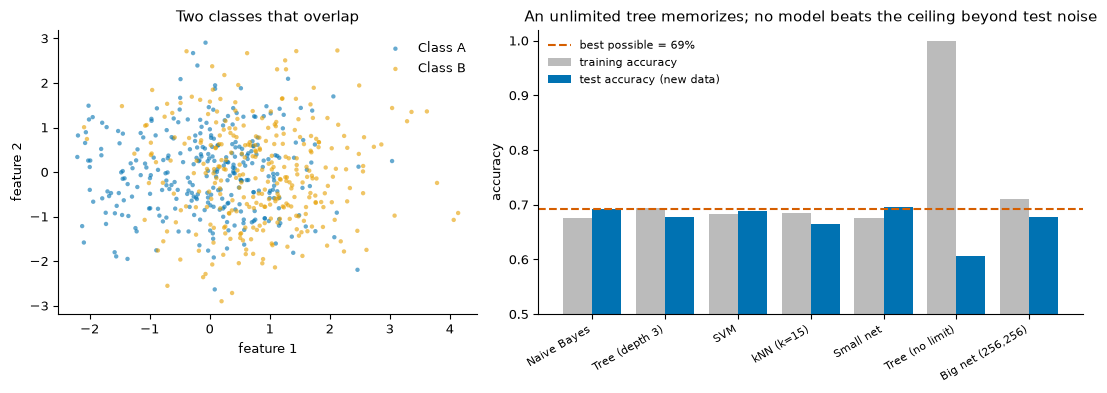

In [10]:
rng = np.random.default_rng(383); sep = 1.0                              # sep = distance between the two class centers, in units of spread
def two_blobs(n):                                                        # two Gaussian classes described by 2 features
    return np.vstack([rng.normal([0, 0], 1, (n, 2)), rng.normal([sep, 0], 1, (n, 2))]), np.r_[np.zeros(n), np.ones(n)]
Xtr, ytr = two_blobs(300); Xte, yte = two_blobs(5000)                    # small training set, large test set
best_possible = norm.cdf(sep/2)                                          # Bayes accuracy: the highest any classifier can reach on these two Gaussians
toy_models = {"Naive Bayes": GaussianNB(), "Tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=0),
              "SVM": make_pipeline(StandardScaler(), SVC()), "kNN (k=15)": make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
              "Small net": make_pipeline(StandardScaler(), MLPClassifier((8,), max_iter=2000, random_state=0)),
              "Tree (no limit)": DecisionTreeClassifier(random_state=0),
              "Big net (256,256)": make_pipeline(StandardScaler(), MLPClassifier((256, 256), max_iter=3000, random_state=0))}
toy = {k: (m.fit(Xtr, ytr).score(Xtr, ytr), m.score(Xte, yte)) for k, m in toy_models.items()}

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.3]})
for k, col in [(0, "#0072B2"), (1, "#E69F00")]: a.scatter(*Xtr[ytr == k].T, s=10, alpha=.6, color=col, label=f"Class {'AB'[k]}", edgecolor="none")
a.set(xlabel="feature 1", ylabel="feature 2", title="Two classes that overlap"); a.legend(frameon=False)
x = np.arange(len(toy)); b.bar(x - .2, [v[0] for v in toy.values()], .4, color="#BBBBBB", label="training accuracy")
b.bar(x + .2, [v[1] for v in toy.values()], .4, color="#0072B2", label="test accuracy (new data)")
b.axhline(best_possible, color="#D55E00", ls="--", label=f"best possible = {best_possible:.0%}")
b.set_ylim(0.5, 1.02); b.set_xticks(x); b.set_xticklabels(toy, rotation=30, ha="right", fontsize=8)
b.set(ylabel="accuracy", title="An unlimited tree memorizes; no model beats the ceiling beyond test noise"); b.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()

* **Animation:** the same two Gaussian classes, with Class B sliding toward Class A over 12 frames (about 10 s, then it repeats)
* left: the density of each class along feature 1; the gray area is the overlap, where even the best boundary (dashed line, halfway between the centers) must make errors
* right and title: the best possible accuracy, norm.cdf(sep/2), falls from 92% to 50% (a coin flip) as the centers meet; the dotted line is the toy example above (sep = 1, 69%)
* the GIF is built in memory and stored in the notebook, so no file is needed; the PDF shows only the first frame (sep = 2.75, 92%)

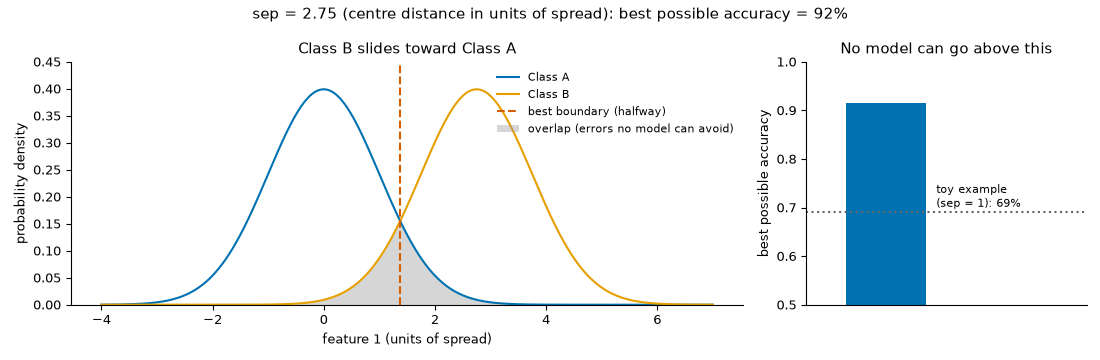

In [11]:
seps = np.linspace(2.75, 0, 12)                                          # 12 frames: centers 2.75 spreads apart down to 0 (same place), includes sep = 1
z = np.linspace(-4, 7, 400)                                              # feature 1 axis; the two classes differ only in feature 1
gfig, (ga, gb) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2.4, 1]})
pa, = ga.plot(z, norm.pdf(z), color="#0072B2", label="Class A")
pb, = ga.plot(z, norm.pdf(z), color="#E69F00", label="Class B")
cut = ga.axvline(0, color="#D55E00", ls="--", label="best boundary (halfway)")
ga.set(xlabel="feature 1 (units of spread)", ylabel="probability density", ylim=(0, 0.45), title="Class B slides toward Class A")
bar = gb.bar([0], [0.5], 0.4, color="#0072B2")[0]
gb.axhline(best_possible, color="#666666", ls=":"); gb.text(0.25, best_possible + 0.01, f"toy example\n(sep = 1): {best_possible:.0%}", fontsize=8)
gb.set(xlim=(-0.4, 1.0), ylim=(0.5, 1.0), xticks=[], ylabel="best possible accuracy", title="No model can go above this")
shade = []

def draw(k):                                                             # one frame: move Class B, redraw the overlap, update the bar and the title
    sep_k = seps[k]; acc = norm.cdf(sep_k/2)                             # best possible (Bayes) accuracy for centers sep_k apart
    pb.set_ydata(norm.pdf(z, loc=sep_k)); cut.set_xdata([sep_k/2]*2)
    for s in shade: s.remove()
    shade[:] = [ga.fill_between(z, np.minimum(norm.pdf(z), norm.pdf(z, loc=sep_k)), color="#999999", alpha=.4, lw=0, label="overlap (errors no model can avoid)")]
    bar.set_height(acc)
    gfig.suptitle(f"sep = {sep_k:.2f} (centre distance in units of spread): best possible accuracy = {acc:.0%}")

draw(0); ga.legend(frameon=False, fontsize=8, loc="upper right"); gfig.tight_layout()
gif = io.BytesIO(); gif.name = "overlap.gif"                             # in-memory buffer; the name only tells Pillow to encode a GIF
FuncAnimation(gfig, draw, frames=len(seps)).save(gif, writer=MemoryGIF(fps=1.2))   # 12 frames at 1.2 per second = 10 s
draw(0); still = io.BytesIO(); gfig.savefig(still, format="png"); plt.close(gfig)  # frame 1 as a PNG, for the PDF export
display({"text/html": f'<img src="data:image/gif;base64,{base64.b64encode(gif.getvalue()).decode()}">',   # animated in Jupyter and VS Code
         "image/png": base64.b64encode(still.getvalue()).decode()}, raw=True)                                # still frame where HTML is not shown

### Workflow: Can We Tell That Classes Cannot Be Separated, and What Then?

1. Generate data and look for overlap with an easy first test
2. Add wearer and battery variation and map every pair of causes
3. Ask if the hardest pair is a model limit, a data limit or true overlap (at s = 2 and s = 4)
4. Test which sensors help, and catch a sensor that leaks the answer
5. Remove the suspected source of overlap to prove it is the cause
6. Let the model abstain ("not sure") where overlap remains
7. Explore single trials with an interactive simulator

### 1. Generate the Datasets

* four datasets with the same recipe but growing variation: s = 0 (identical wearer every time), s = 1, s = 2 and s = 4
* the s = 2 and s = 4 sets are bigger (1,500 training and 600 test trials each) so learning curves have room; this takes about 160 s on a laptop

In [12]:
import time; t0 = time.time()
D0 = make_dataset("slow", 0.0, 12, 12, 60, 60, master_seed=1)            # s = 0: every wearer and battery identical
D1 = make_dataset("slow", 1.0, 12, 12, 60, 60, master_seed=2)            # s = 1: moderate variation
D2 = make_dataset("slow", 2.0, 60, 40, 600, 200, master_seed=3)          # s = 2: main dataset, larger so learning curves have room
D4 = make_dataset("slow", 4.0, 60, 40, 600, 200, master_seed=5)          # s = 4: doubled variation, same size as D2
print(f"simulated {len(D0)+len(D1)+len(D2)+len(D4)} trials in {time.time()-t0:.0f} s")
D2.groupby(["split", "cause"]).size().unstack().rename(columns=SHORT)

simulated 5040 trials in 146 s


cause,Weaker motor,Sensor offset,Sensor drift,Healthy,Loose strap,Extra load
split,,,,,,
test,80,80,80,200,80,80
train,180,180,180,600,180,180


### 2. Map Every Pair of Causes

* for each of the 15 pairs, train five model families (naive Bayes, tree, SVM, kNN, neural net) and keep the best test score, so a weak model cannot be mistaken for overlap
* the first attempt (s = 0) was too easy, with every pair at 1.00; variation is what creates overlap
* s = 4 doubles the variation again to look for a true ceiling; the hardest pairs at s = 2 and s = 4 are printed below the maps
* at s = 4 the mean over pairs drops to 0.971; healthy vs weaker motor (0.86) and healthy vs extra load (0.91) are the hardest

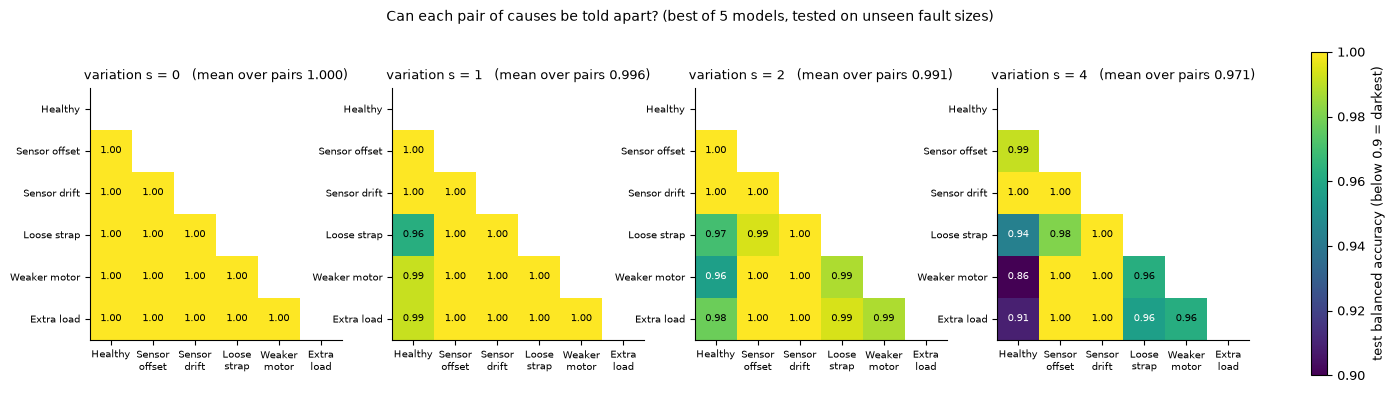

hardest pairs at s = 2
 a        b                  
healthy  actuator_gain_loss     0.956
         interface_looseness    0.970
         load_mass              0.978
Name: test, dtype: float64
hardest pairs at s = 4
 a        b                  
healthy  actuator_gain_loss     0.860
         load_mass              0.909
         interface_looseness    0.944
Name: test, dtype: float64


In [13]:
cols = channel_columns(D2, MAIN)                                         # 20 features from 4 sensors
S0, S1, S2, S4 = [pair_scores(D, cols) for D in (D0, D1, D2, D4)]
fig, axs = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, S, s in zip(axs, [S0, S1, S2, S4], [0, 1, 2, 4]): im = draw_pair_map(ax, S, f"variation s = {s}   (mean over pairs {S.groupby(["a", "b"]).test.max().mean():.3f})")
fig.colorbar(im, ax=axs, fraction=0.015, label="test balanced accuracy (below 0.9 = darkest)")
fig.suptitle("Can each pair of causes be told apart? (best of 5 models, tested on unseen fault sizes)", fontsize=10); plt.show()
hard = S2.groupby(["a", "b"]).test.max().sort_values().head(3).round(3); print("hardest pairs at s = 2\n", hard)
hard4 = S4.groupby(["a", "b"]).test.max().sort_values().head(3).round(3); print("hardest pairs at s = 4\n", hard4)

### 3. Is the Hardest Pair a Model Limit, a Data Limit or True Overlap?

* **healthy vs weaker motor** is the hardest pair at s = 2 (0.956); a weaker motor looks like a battery that has sagged
* weak models fail (naive Bayes 0.67, kNN 0.69) and a tree with no depth limit memorizes (train 1.00, test 0.91), but SVM (0.96) and the 256-unit net (0.97) do well, so it is not a ceiling for every model

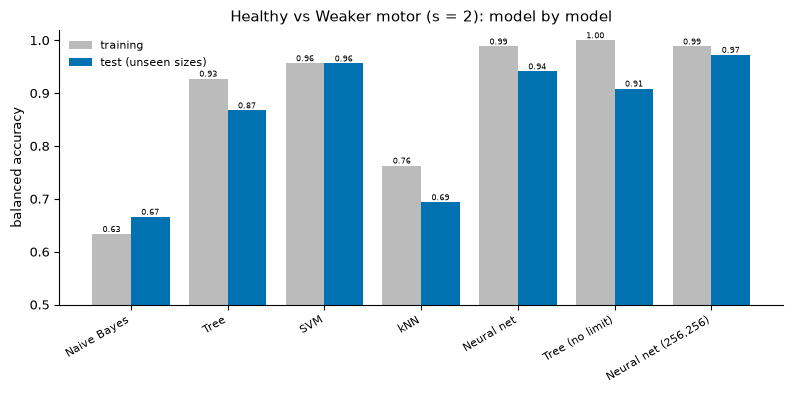

In [14]:
a, b = hard.index[0]                                                     # the hardest pair at s = 2
big = {**model_zoo(), "Tree (no limit)": DecisionTreeClassifier(class_weight="balanced", random_state=0),
       "Neural net (256,256)": make_pipeline(StandardScaler(), MLPClassifier((256, 256), max_iter=600, random_state=0))}
rows = pd.DataFrame(Parallel(n_jobs=-1)(delayed(fit_pair)(D2, a, b, cols, n, m) for n, m in big.items()))

fig, ax1 = plt.subplots(figsize=(8, 4))
x = np.arange(len(rows)); ax1.bar(x - .2, rows.train, .4, color="#BBBBBB", label="training"); ax1.bar(x + .2, rows.test, .4, color="#0072B2", label="test (unseen sizes)")
ax1.set_ylim(0.5, 1.02); ax1.set_xticks(x); ax1.set_xticklabels(rows.model, rotation=30, ha="right", fontsize=8)
ax1.set(ylabel="balanced accuracy", title=f"{SHORT[a]} vs {SHORT[b]} (s = 2): model by model"); ax1.legend(frameon=False, fontsize=8, loc="upper left")
for bars in ax1.containers: ax1.bar_label(bars, fmt="%.2f", fontsize=6)          # print each score on its bar
fig.tight_layout(); plt.show()

**Learning curves at s = 2 and s = 4**

* the hardest pair at each level, with the same training sizes (40 to 640 trials, five random subsets each); the legend lists the mean at each size
* s = 2: SVM accuracy climbs from 0.79 to 0.95 and is still rising, though more slowly, so a small dataset would have faked a ceiling
* s = 4: the hardest pair is again healthy vs weaker motor; SVM climbs from 0.67 to 0.85 but gains only about 0.02 on the last doubling (320 to 640 trials), so the curve is flattening below 0.9; it has not fully stopped rising, so more data could still add a little

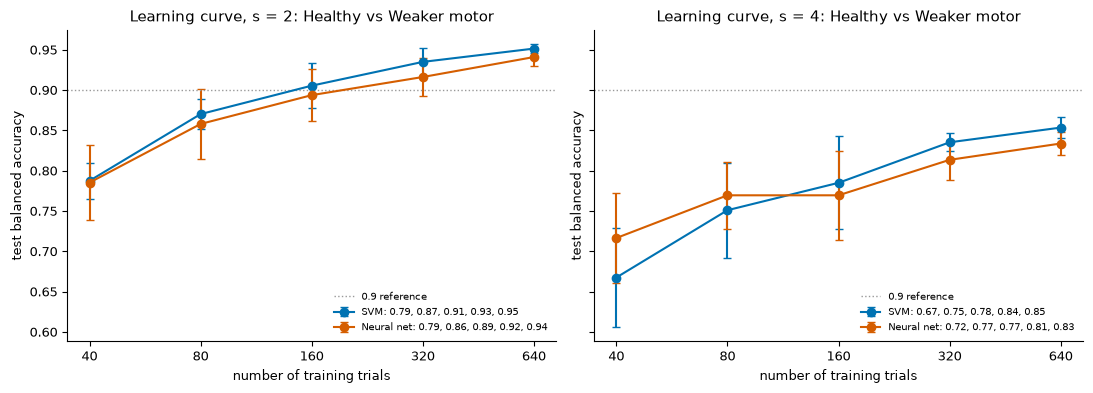

In [15]:
sizes = [40, 80, 160, 320, 640]                                          # same training sizes for both variation levels
a4, b4 = hard4.index[0]                                                  # the hardest pair at s = 4
curves = {2: (a, b, learning_curve(D2, a, b, cols, sizes)), 4: (a4, b4, learning_curve(D4, a4, b4, cols, sizes))}
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (s, (p, q, c)) in zip(axs, curves.items()):
    for n, col in [("SVM", "#0072B2"), ("Neural net", "#D55E00")]:
        d = c[c.model == n]; ax.errorbar(d.n, d["mean"], d["std"], marker="o", color=col, capsize=3, label=f"{n}: " + ", ".join(f"{v:.2f}" for v in d["mean"]))
    ax.axhline(0.9, color="#999999", ls=":", lw=1, label="0.9 reference")
    ax.set_xscale("log"); ax.set_xticks(sizes, [str(z) for z in sizes]); ax.minorticks_off()
    ax.set(xlabel="number of training trials", ylabel="test balanced accuracy", title=f"Learning curve, s = {s}: {SHORT[p]} vs {SHORT[q]}")
    ax.legend(frameon=False, fontsize=7, loc="lower right")
fig.tight_layout(); plt.show()

**Is the s = 4 ceiling stable?**

* regenerate the two worst s = 4 pairs with a different seed (master_seed = 6, same size and recipe) and refit all five models; the best model's training and test accuracy are listed for both seeds
* healthy vs weaker motor: best test accuracy 0.860 and 0.858, with training accuracy 0.87 and 0.89, so the model is not memorizing and the result is stable
* healthy vs extra load: 0.909 and 0.896, at about 0.9

In [16]:
worst = list(hard4.index[:2])                                            # the two worst pairs at s = 4 (both against healthy)
R6 = make_dataset("slow", 4.0, 60, 40, 600, 200, causes=tuple(q for _, q in worst), master_seed=6)   # same recipe, new seed
S6 = pd.DataFrame(Parallel(n_jobs=-1)(delayed(fit_pair)(R6, p, q, cols, n, model_zoo()[n]) for p, q in worst for n in model_zoo()))
best = lambda S: (S[S.b.isin([q for _, q in worst]) & (S.a == "healthy")].sort_values("test").groupby("b").tail(1)
                  .set_index("b")[["model", "train", "test"]].rename(index=SHORT))
pd.concat({"master_seed = 5 (D4)": best(S4), "master_seed = 6": best(S6)}, axis=1).round(3)

master_seed = 5 (D4)               master_seed = 6              
                            model  train   test           model  train   test
b                                                                            
Weaker motor                  SVM  0.870  0.860             SVM  0.894  0.858
Extra load             Neural net  0.941  0.909      Neural net  0.908  0.896

### 4. Which Sensors Help, and Is Any Sensor Cheating?

* adding sensors one at a time lifts healthy vs weaker motor from 0.85 to 0.96, mostly from the strap-torque channel
* strap tension seems to fix healthy vs loose strap (0.97 to 1.00), but the right plot shows why this is a leak: a loose strap lowers the strap preload, which the sensor reads almost directly, so I exclude tension from the main results

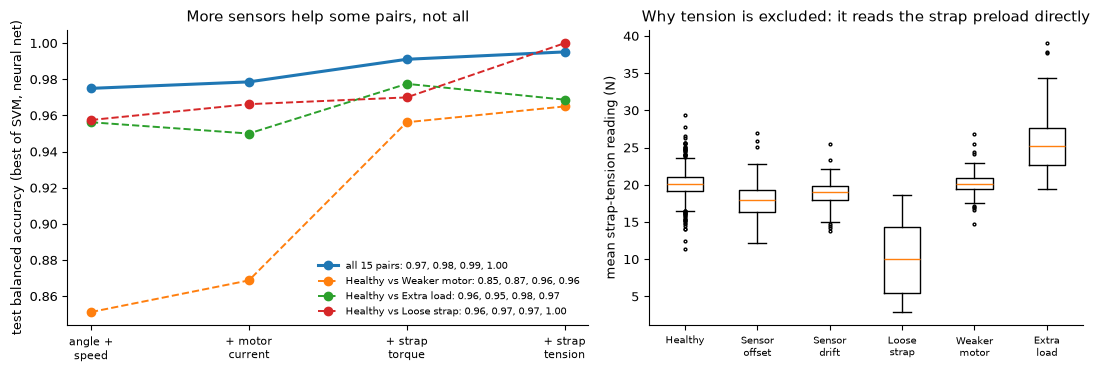

In [17]:
SUBSETS = {"angle +\nspeed": ["enc_err", "gyro"], "+ motor\ncurrent": ["enc_err", "gyro", "current"],
           "+ strap\ntorque": MAIN, "+ strap\ntension": MAIN + ["strap_tension"]}
watch = [("healthy", "actuator_gain_loss"), ("healthy", "load_mass"), ("healthy", "interface_looseness")]
res = []
for name, chs in SUBSETS.items():
    S = pair_scores(D2, channel_columns(D2, chs), ["SVM", "Neural net"]); g = S.groupby(["a", "b"]).test.max()
    res.append({"sensors": name, "all 15 pairs": g.mean(), **{f"{SHORT[p]} vs {SHORT[q]}": g[(p, q)] for p, q in watch}})
res = pd.DataFrame(res).set_index("sensors")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
for col, st in zip(res.columns, ["-", "--", "--", "--"]): ax1.plot(range(4), res[col], marker="o", ls=st, lw=2.2 if col.startswith("all") else 1.4,
                                                         label=f"{col}: " + ", ".join(f"{v:.2f}" for v in res[col]))   # values in the legend
ax1.set_xticks(range(4)); ax1.set_xticklabels(res.index, fontsize=8); ax1.set(ylabel="test balanced accuracy (best of SVM, neural net)", title="More sensors help some pairs, not all"); ax1.legend(frameon=False, fontsize=7)
tr = D2[D2.split == "train"]
ax2.boxplot([tr[tr.cause == c].strap_tension_mean for c in CAUSES], tick_labels=[SHORT[c].replace(" ", "\n") for c in CAUSES], flierprops=dict(markersize=2))
ax2.set_xticklabels([SHORT[c].replace(" ", "\n") for c in CAUSES], fontsize=7)
ax2.set(ylabel="mean strap-tension reading (N)", title="Why tension is excluded: it reads the strap preload directly")
fig.tight_layout(); plt.show()

### 5. Prove the Source of Overlap by Removing It

* healthy vs extra load stays below perfect even with all variation, and my suspect is forearm mass: a heavier arm looks like an added load
* test: generate the same data with forearm-mass variation switched off and compare (SVM and neural net, same size and seeds)
* this dataset is smaller than the main one (40 trials per size, 300 healthy), so scores sit below the main map's 0.978; compare only its two rows with each other

In [18]:
no_mass = {**SPREAD, "m_h": 0.0}                                         # same wearer variation, but forearm mass identical for everyone
ablate = []
for label, sp in [("all variation on", SPREAD), ("forearm-mass variation off", no_mass)]:
    d = make_dataset("slow", 2.0, 40, 40, 300, 150, causes=("load_mass",), spread=sp, master_seed=4)
    r = [fit_pair(d, "healthy", "load_mass", channel_columns(d, MAIN), n, model_zoo()[n]) for n in ["SVM", "Neural net"]]
    ablate.append({"setting": label, **{x["model"]: x["test"] for x in r}})
ablate = pd.DataFrame(ablate).set_index("setting"); ablate["mean"] = ablate.mean(axis=1); ablate.round(3)

,SVM,Neural net,mean
setting,,,
all variation on,0.93,0.93,0.93
forearm-mass variation off,1.00,1.00,1.00


### 6. Let the Model Say "Not Sure"

* a 6-class neural net outputs a probability for each cause; if the highest is below 0.8 it abstains
* the threshold 0.8 was chosen before looking at results, and the test set is balanced (80 trials per cause)
* left: the trade of coverage for accuracy; right: where the model abstains (mostly healthy, weaker motor, extra load and loose strap, the causes that overlap)

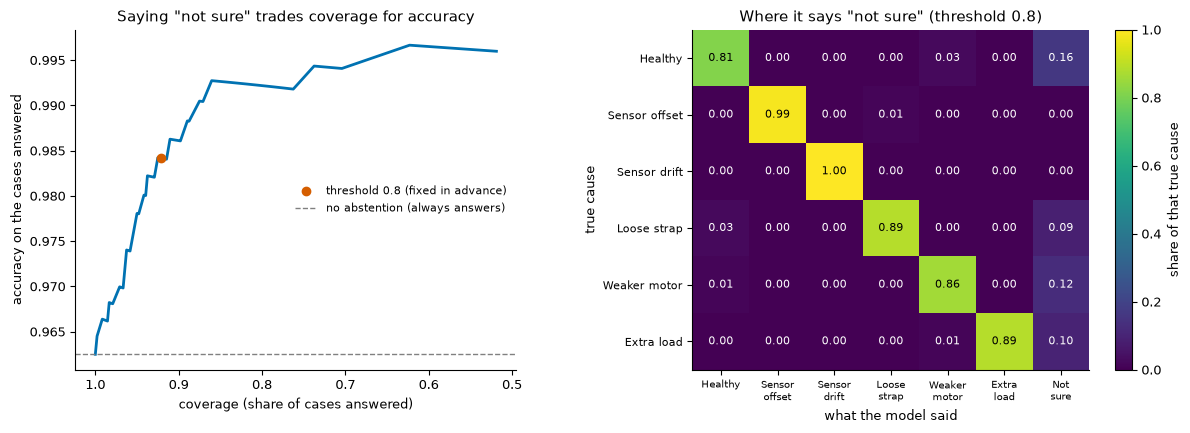

no abstention: 0.963  |  threshold 0.8: answers 92% of cases, 0.984 correct


In [19]:
tr, te = D2[D2.split == "train"], D2[D2.split == "test"]
te = te.groupby("cause").sample(n=80, random_state=1)                    # balanced test set: 80 per cause
code = {c: i for i, c in enumerate(CAUSES)}; names = [SHORT[c] for c in CAUSES]
net = make_pipeline(StandardScaler(), MLPClassifier((64, 64), max_iter=1500, random_state=0)).fit(tr[cols].values, tr.cause.map(code))
P = net.predict_proba(te[cols].values); pred, conf, truth = P.argmax(1), P.max(1), te.cause.map(code).values
TAU = 0.8                                                                # confidence threshold, fixed in advance (not tuned on the test set)
answered = conf >= TAU
sweep = [(np.mean(conf >= t), np.mean(pred[conf >= t] == truth[conf >= t])) for t in np.linspace(0.3, 0.999, 100) if np.sum(conf >= t) >= 30]
C = np.zeros((6, 7))
for y, p, ok in zip(truth, pred, answered): C[y, p if ok else 6] += 1
C /= C.sum(1, keepdims=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.15]})
ax1.plot(*zip(*sweep), color="#0072B2", lw=2); ax1.scatter(answered.mean(), np.mean(pred[answered] == truth[answered]), color="#D55E00", zorder=5, label=f"threshold {TAU} (fixed in advance)")
ax1.axhline(np.mean(pred == truth), color="0.5", ls="--", lw=1, label="no abstention (always answers)"); ax1.invert_xaxis()
ax1.set(xlabel="coverage (share of cases answered)", ylabel="accuracy on the cases answered", title='Saying "not sure" trades coverage for accuracy'); ax1.legend(frameon=False, fontsize=8, loc="center right")
im = ax2.imshow(C, vmin=0, vmax=1, cmap="viridis"); ax2.set_xticks(range(7)); ax2.set_xticklabels([n.replace(" ", "\n") for n in names] + ["Not\nsure"], fontsize=7); ax2.set_yticks(range(6)); ax2.set_yticklabels(names, fontsize=8)
for i in range(6):
    for j in range(7): ax2.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if C[i, j] < 0.5 else "black")
ax2.set(xlabel="what the model said", ylabel="true cause", title=f'Where it says "not sure" (threshold {TAU})'); fig.colorbar(im, ax=ax2, fraction=0.04, label="share of that true cause")
fig.tight_layout(); plt.show()
print(f"no abstention: {np.mean(pred == truth):.3f}  |  threshold {TAU}: answers {answered.mean():.0%} of cases, {np.mean(pred[answered] == truth[answered]):.3f} correct")

### 7. Explore One Trial Interactively

* choose a cause, a fault size (0.1 to 2.0 times typical; ignored for healthy) and the wearer variation s (0 to 4); "new random trial" draws a new wearer and new sensor noise
* left: forearm and exoskeleton at the moment of largest strap stretch (after the 1 s start-up), with the strap gauge; middle: angle error and motor current; right: the six-class neural net from step 6 (trained once, at s = 2) with its probabilities and "not sure" when the top one is below 0.8
* sizes outside 0.5 to 1.5 times typical and variation other than s = 2 were not in training, so answers there are extrapolation
* the snapshot below uses the default values (loose strap, size 1.0, s = 2, trial seed 1), so it shows without the controls

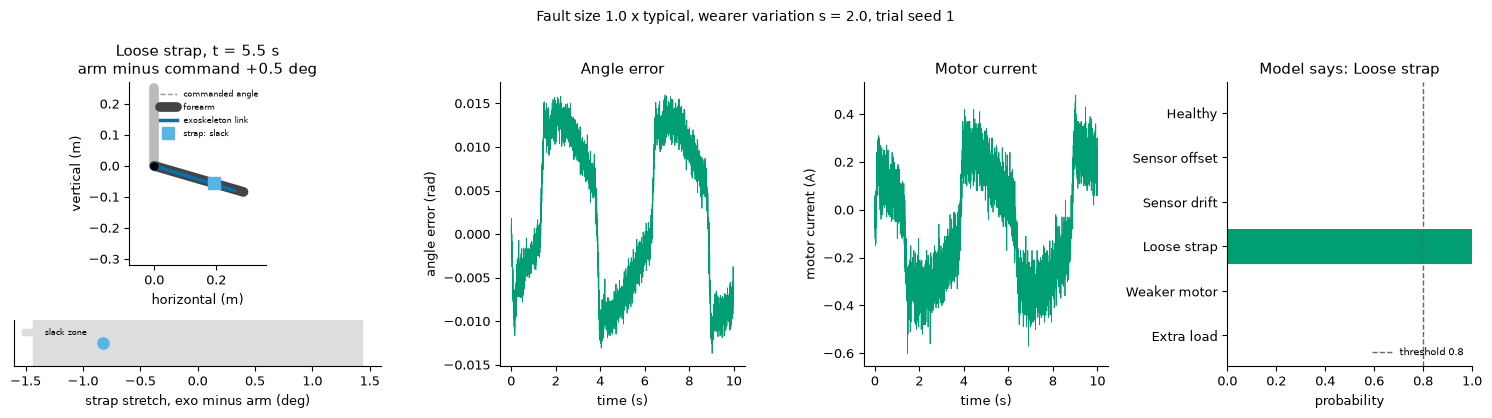

In [20]:
def show_trial(cause="interface_looseness", size=1.0, s=2.0, seed=1):
    """Simulate one trial; draw the arm, two sensor traces and the six-class net's answer ("not sure" below TAU)."""
    p = make_params(cause, size, seed, s)
    t, sig, truth = simulate(p, "slow", seed, return_truth=True)
    prob = net.predict_proba(pd.DataFrame([summarize(t, sig)])[cols].values)[0]   # the same 20 features as in training
    k = int(np.argmax(np.abs(truth["q_exo"] - truth["q_arm"])*(t >= 1.0)))   # largest strap stretch after the 1 s start-up
    fig = plt.figure(figsize=(15, 4.2)); grid = fig.add_gridspec(2, 4, height_ratios=[4, 1], width_ratios=[1.5, 1, 1, 1])
    draw_arm(fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[1, 0]), truth, k, p, f"{SHORT[cause]}, t = {t[k]:.1f} s")
    for j, (ch, label) in enumerate([("enc_err", "angle error (rad)"), ("current", "motor current (A)")]):
        ax = fig.add_subplot(grid[:, j + 1]); ax.plot(t, sig[ch], color=COLOR[cause], lw=0.6)
        ax.set(xlabel="time (s)", ylabel=label, title=label.split(" (")[0].capitalize())
    ax = fig.add_subplot(grid[:, 3]); ax.barh(names, prob, color=[COLOR[c] for c in CAUSES]); ax.invert_yaxis()
    ax.axvline(TAU, color="#666666", ls="--", lw=1, label=f"threshold {TAU}")
    answer = names[prob.argmax()] if prob.max() >= TAU else "not sure"
    ax.set(xlim=(0, 1), xlabel="probability", title=f"Model says: {answer}"); ax.legend(frameon=False, fontsize=7, loc="lower right")
    fig.suptitle(f"Fault size {size:.1f} x typical, wearer variation s = {s:.1f}, trial seed {seed}", fontsize=10); fig.tight_layout(); plt.show()

show_trial()                                                             # snapshot with the default values, saved in the notebook

* the live controls; they need a running kernel and the ipywidgets package (in a PDF, on GitHub or without ipywidgets only the snapshot above is shown)
* sliders redraw when released, and each change simulates one new 10 s trial (about a second)

In [21]:
def simulator_widget():
    """Controls for show_trial(); the figure redraws when a control changes."""
    style = {"description_width": "initial"}
    cause = widgets.Dropdown(options=[(SHORT[c], c) for c in CAUSES], value="interface_looseness", description="cause", style=style)
    size = widgets.FloatSlider(value=1.0, min=0.1, max=2.0, step=0.1, description="fault size", continuous_update=False, style=style)
    s = widgets.FloatSlider(value=2.0, min=0.0, max=4.0, step=0.5, description="wearer variation s", continuous_update=False, style=style)
    seed = widgets.IntText(value=1, layout=widgets.Layout(display="none"))   # hidden; the button changes it
    new = widgets.Button(description="new random trial")
    new.on_click(lambda _: setattr(seed, "value", seed.value + 1))
    out = widgets.interactive_output(show_trial, dict(cause=cause, size=size, s=s, seed=seed))
    return widgets.VBox([widgets.HBox([cause, size, s, new]), out])

if widgets: display(simulator_widget())                                  # live controls (need a running kernel)
else: print("Live controls need ipywidgets (pip install ipywidgets); the snapshot above shows the default trial.")

### Results

**Was the hypothesis right?** I expected some pairs of causes to be truly inseparable. Up to s = 2 they were not, but overlap and data limits both showed up, and a checklist separates them; at s = 4 one pair (healthy vs weaker motor) stays near 0.86 with two seeds and a flattening learning curve, which is consistent with true overlap.

| Check | What I saw | What it means |
|---|---|---|
| Easy first test (s = 0) | all pairs 1.00 | no overlap without variation |
| Variation s = 1, 2 | mean pair accuracy 0.996, 0.991; worst pair 0.962, 0.956 | variation creates overlap, but small |
| Variation s = 4 | mean pair accuracy 0.971; worst pairs 0.860 (healthy vs weaker motor) and 0.909 (healthy vs extra load) | more variation, more overlap |
| Train-test gap | tree with no limit 1.00 vs 0.91; kNN and naive Bayes low on both | memorizing and underfitting, not overlap |
| Learning curve, s = 2 | SVM 0.79 to 0.95, still rising at 640 trials | data limit, not a ceiling |
| Learning curve, s = 4 | SVM 0.67 to 0.85, gaining about 0.02 on the last doubling | flattening below 0.9; consistent with overlap, not proof |
| New seed, s = 4 | 0.860 vs 0.858 (weaker motor), 0.909 vs 0.896 (extra load); train 0.87 and 0.89 for weaker motor | the s = 4 result is stable and not memorized |
| Model families agree? | SVM and 256-unit net near 0.96 and 0.97, others lower | the pair is separable; weak models are the limit |
| Ablation (arm mass off) | healthy vs extra load 0.93 to 1.00 | forearm mass was a real source of overlap |
| Sensor leak | tension reads strap preload | excluded, or accuracy would be inflated |
| Abstention at 0.8 | 0.963 to 0.984, answering 92% of cases | removes 11 of the 18 errors, at the cost of 38 abstentions |

* **Limits:** a single simulated joint, placeholder parameters, variation chosen by me, and no real data; the conclusions are about the method, not about a real exoskeleton
* **Limits:** the best of five models is picked on the test set, which slightly flatters the scores; a separate validation split would remove this
* **Limits:** these are classifier results (statistical separability), not proof of what is identifiable in principle
* **Next:** estimate the Bayes error at s = 4 directly from the simulator to confirm the ceiling, choose models on a separate validation split, and compare the abstention threshold with a calibrated probability

### Parting Comments

* the practical lesson is that "the classifier cannot do better" is a claim that needs evidence: a train-test gap, a learning curve, several model families, an ablation and a second random seed; at s = 4 that evidence points to real overlap for healthy vs weaker motor
* the interactive simulator (step 7) lets you change the cause, fault size and wearer variation and see when the model says "not sure"
* I am a graduate student in mechanical engineering (dynamic systems and controls) interested in actuators, wearable robotics and machine learning for diagnosis; this workflow is open for anyone to run
* I am always looking for research opportunities and collaborations in controls and wearable robotics, and I am open to roles in robotics and actuator controls

[Portfolio](https://amansanadhya.github.io/) | [LinkedIn](https://www.linkedin.com/in/amansanadhya)

#### About the Course and the Instructor

* this workflow was built for **Subsurface Machine Learning** at The University of Texas at Austin, taught by Prof. Michael Pyrcz
* the course teaches machine learning with hands-on Python demonstrations, an open [Applied Machine Learning in Python e-book](https://geostatsguy.github.io/MachineLearningDemos_Book/) and recorded lectures on [YouTube](https://www.youtube.com/channel/UCLqEr-xV-ceHdXXXrTId5ig)
* its habit of checking a model, not just fitting it (train-test gaps, tuning, uncertainty), is what led me to ask when a model's limit comes from the data itself
* more about the instructor: [website](http://michaelpyrcz.com) and [GitHub](https://github.com/GeostatsGuy)

### Code Sources and References

* simulator, features, models and plots: written by me for this project; the simulator is a compact rewrite of my own earlier exoskeleton diagnosis code (Aman Sanadhya, 2026, not published)
* model families, the scaling-then-model pipeline and balanced accuracy: scikit-learn, Pedregosa et al., 2011, *Journal of Machine Learning Research* 12, 2825-2830, https://scikit-learn.org
* overfitting, train-test gaps, learning curves and the model families follow the course lectures and e-book: Pyrcz, M.J., 2024, *Applied Machine Learning in Python: a Hands-on Guide with Code*, https://geostatsguy.github.io/MachineLearningDemos_Book/
* Bayes error: Duda, R.O., Hart, P.E. and Stork, D.G., 2001, *Pattern Classification*, 2nd ed., Wiley
* parallel runs: joblib, https://joblib.readthedocs.io
* GIF animations: Matplotlib animation (Hunter, 2007) with Pillow, https://python-pillow.org; interactive controls: ipywidgets, https://ipywidgets.readthedocs.io
* arrays, tables, plots and the normal distribution: NumPy (Harris et al., 2020, *Nature* 585, 357-362), pandas (McKinney, 2010, *Proc. 9th Python in Science Conference*, 56-61), Matplotlib (Hunter, 2007, *Computing in Science & Engineering* 9(3), 90-95), SciPy (Virtanen et al., 2020, *Nature Methods* 17, 261-272)
* reject option (abstaining when unsure): Chow, C.K., 1970, On optimum recognition error and reject tradeoff, *IEEE Transactions on Information Theory* 16(1), 41-46
* notebook layout: Pyrcz, M.J., PGE 383 project template, The University of Texas at Austin